In [1]:
import numpy as np
import pandas as pd
df=pd.read_csv("yield_df.csv")
raw = df.copy()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  object 
 2   Item                           28242 non-null  object 
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.7+ MB


In [2]:
climate_cols = ["average_rain_fall_mm_per_year", "avg_temp"]
for c in climate_cols:
    print(f"{c}: zeros = {(df[c] == 0).sum()}, negatives = {(df[c] < 0).sum()}")
print("Zero yields:", (df["hg/ha_yield"] == 0).sum())
df[climate_cols] = df[climate_cols].replace(0, np.nan)
for c in climate_cols:
    df[c] = df[c].fillna(df.groupby("Area")[c].transform("median"))
    df[c] = df[c].fillna(df[c].median())
print("\nMissing values after handling:", df[climate_cols].isnull().sum().sum())

average_rain_fall_mm_per_year: zeros = 0, negatives = 0
avg_temp: zeros = 0, negatives = 0
Zero yields: 0

Missing values after handling: 0


In [3]:
yield_trends = df.groupby(['Year', 'Item'])['hg/ha_yield'].mean().reset_index()
trend_matrix = yield_trends.pivot(index='Year', columns='Item', values='hg/ha_yield')
print(trend_matrix)

Item        Cassava         Maize  Plantains and others       Potatoes  \
Year                                                                     
1990  119292.738636  27706.041916         107239.208333  173127.063953   
1991  123852.761364  27900.958084         108768.708333  169009.000000   
1992  126751.516854  27962.977528         103993.291667  171164.989130   
1993  127019.561798  28997.363128         105399.375000  174366.843243   
1994  130528.955056  28344.642458         105555.750000  175015.697297   
1995  135052.123596  29200.106145         108046.000000  179542.600000   
1996  127985.494382  30763.502793         103516.708333  183527.491892   
1997  126310.359551  31915.184358         103477.500000  186404.416216   
1998  135821.213483  32526.022346         104212.583333  182332.556757   
1999  137388.707865  33003.357542         105620.250000  192202.324324   
2000  145293.000000  33590.622222         104746.791667  194626.941176   
2001  149279.842697  34558.016667     

In [6]:
!pip install geopy

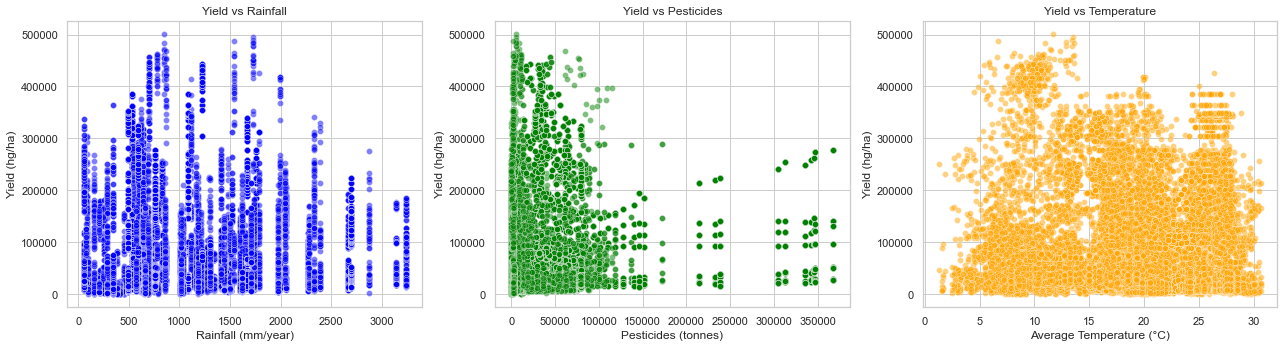

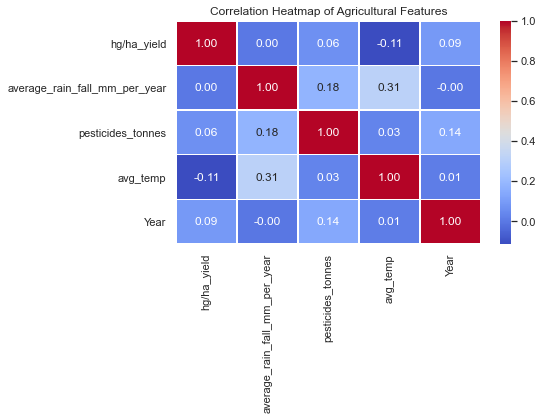

In [ ]:
%matplotlib inline

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import folium
from geopy.geocoders import Nominatim
from IPython.display import display
df = pd.read_csv('yield_df.csv')
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='average_rain_fall_mm_per_year', y='hg/ha_yield', ax=axes[0], alpha=0.5, color='blue')
axes[0].set_title('Yield vs Rainfall')
axes[0].set_xlabel('Rainfall (mm/year)')
axes[0].set_ylabel('Yield (hg/ha)')

sns.scatterplot(data=df, x='pesticides_tonnes', y='hg/ha_yield', ax=axes[1], alpha=0.5, color='green')
axes[1].set_title('Yield vs Pesticides')
axes[1].set_xlabel('Pesticides (tonnes)')
axes[1].set_ylabel('Yield (hg/ha)')

sns.scatterplot(data=df, x='avg_temp', y='hg/ha_yield', ax=axes[2], alpha=0.5, color='orange')
axes[2].set_title('Yield vs Temperature')
axes[2].set_xlabel('Average Temperature (°C)')
axes[2].set_ylabel('Yield (hg/ha)')

plt.tight_layout()
plt.savefig('scatter_plots.png', dpi=300)
plt.show()
plt.close()
plt.figure(figsize=(8, 6))
numeric_df = df[['hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp', 'Year']]
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Agricultural Features')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show()
plt.close()
country_yield = df.groupby('Area')[['hg/ha_yield', 'average_rain_fall_mm_per_year', 'pesticides_tonnes', 'avg_temp']].mean().reset_index()

m = folium.Map(location=[20, 0], zoom_start=2)
geolocator = Nominatim(user_agent="crop_yield_map")

for idx, row in country_yield.iterrows():
    try:
        location = geolocator.geocode(row['Area'], timeout=5)
        if location:
            radius = min(max(row['hg/ha_yield'] / 15000, 3), 25)
            folium.CircleMarker(
                location=[location.latitude, location.longitude],
                radius=radius,
                popup=f"<b>Country:</b> {row['Area']}<br><b>Avg Yield:</b> {row['hg/ha_yield']:.2f} hg/ha<br><b>Rainfall:</b> {row['average_rain_fall_mm_per_year']} mm",
                color='green',
                fill=True,
                fill_color='green',
                fill_opacity=0.6
            ).add_to(m)
    except Exception as e:
        continue

m.save('folium_map.html')
display(m)

In [2]:
import pandas as pd
import scipy.stats as stats
df=pd.read_csv("yield_df.csv")
r, p = stats.pearsonr(df['average_rain_fall_mm_per_year'], df['hg/ha_yield'])

print(f"Pearson correlation coefficient (r): {r:.4f}")
print(f"p-value: {p:.4f}")
w, q = stats.pearsonr(df['average_rain_fall_mm_per_year'], df['avg_temp'])
print(f"Pearson correlation coefficient (r): {w:.4f}")
print(f"p-value: {q:.4f}")

Pearson correlation coefficient (r): 0.0010
p-value: 0.8716
Pearson correlation coefficient (r): 0.3130
p-value: 0.0000
